# Chargement et Analyse exploratoire des données

1. importation des bibliothèques nécessaires

In [64]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn

In [65]:
# Chargement des données
data_path = os.path.join(
    "..", 
    "data", 
    "student_mental_health.csv"
)

try:
    data = pd.read_csv(data_path)
except Exception as e:
    print("Erreur lors de chargement de données.")

data.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [66]:
# Vérification des types
data.dtypes

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object

In [67]:
# Vérification de forme
data.shape

(2000, 17)

In [68]:
# Informations dataset
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [69]:
len(np.unique(data.Student_ID, return_counts=True)[0])

2000

In [70]:
# Suppression de la colonne Student_ID
data = data.drop(
    columns=["Student_ID"], 
    errors="ignore"
)
data.columns.to_list()

['Age',
 'Gender',
 'Year_of_Study',
 'Sleep_Hours',
 'Study_Hours_Per_Week',
 'GPA',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Physical_Activity',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate',
 'Part_Time_Job',
 'Diet_Quality',
 'Previous_Mental_Health_History',
 'Mental_Health_Risk']

In [71]:
# Vérification des valeurs manquantes
data.isna().sum()

Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

In [72]:
# Pourcentage des valeurs manquantes
missing_value_percent = data.isna().mean() * 100
missing_value_percent

Age                               0.00
Gender                            0.00
Year_of_Study                     0.00
Sleep_Hours                       3.10
Study_Hours_Per_Week              0.00
GPA                               1.90
Social_Media_Hours                2.90
Screen_Time_Hours                 0.00
Physical_Activity                 0.00
Financial_Stress                  4.55
Family_Support                    2.70
Attendance_Rate                   2.35
Part_Time_Job                     0.00
Diet_Quality                      3.45
Previous_Mental_Health_History    0.00
Mental_Health_Risk                0.00
dtype: float64

In [73]:
cols_with_na = data.columns[missing_value_percent!=0]
list(cols_with_na)

['Sleep_Hours',
 'GPA',
 'Social_Media_Hours',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate',
 'Diet_Quality']

In [74]:
# Vérification des doublons
data.duplicated().sum()

np.int64(0)

In [75]:
# Vérification des incohérences
data.nunique()

Age                                13
Gender                              3
Year_of_Study                       5
Sleep_Hours                        66
Study_Hours_Per_Week              284
GPA                               182
Social_Media_Hours                 71
Screen_Time_Hours                  95
Physical_Activity                   3
Financial_Stress                   87
Family_Support                     82
Attendance_Rate                   313
Part_Time_Job                       2
Diet_Quality                        3
Previous_Mental_Health_History      2
Mental_Health_Risk                  3
dtype: int64

In [76]:
X = data.drop(columns="Mental_Health_Risk")
y = data["Mental_Health_Risk"]

print(f"Forme des inputs :{str(X.shape):>10}") # python ne permet pas d'appliquer le format >10 sur des tuples
print(f"Forme d'output   :{str(y.shape):>10}")

Forme des inputs :(2000, 15)
Forme d'output   :   (2000,)


In [77]:
# Séparation des colonnes en numérique et catégorique
num_cols = X.select_dtypes(include="number").columns.to_list()
cat_cols = X.select_dtypes(include="str").columns.to_list()

In [78]:
# Vérifier limites
for col in num_cols:
    print(col,":")
    print("\tmin :", np.min(data[col]))
    print("\tmax :", np.max(data[col]))

Age :
	min : 17
	max : 29
Year_of_Study :
	min : 1
	max : 5
Sleep_Hours :
	min : 3.3
	max : 10.0
Study_Hours_Per_Week :
	min : 2.4
	max : 38.3
GPA :
	min : 1.5
	max : 3.66
Social_Media_Hours :
	min : 2.1
	max : 10.0
Screen_Time_Hours :
	min : 3.3
	max : 14.0
Financial_Stress :
	min : 1.4
	max : 10.0
Family_Support :
	min : 1.7
	max : 9.9
Attendance_Rate :
	min : 54.4
	max : 100.0


In [79]:
# Chercher valeurs invalides
for col in cat_cols:
    print(col,":")
    print(f"\tvaleurs uniques :{np.unique(X[col].fillna(""))}")

Gender :
	valeurs uniques :['Female' 'Male' 'Non-binary']
Physical_Activity :
	valeurs uniques :['High' 'Low' 'Moderate']
Part_Time_Job :
	valeurs uniques :['No' 'Yes']
Diet_Quality :
	valeurs uniques :['' 'Average' 'Good' 'Poor']
Previous_Mental_Health_History :
	valeurs uniques :['No' 'Yes']


In [80]:
# Vérification de l'incohérence entre colonnes
regles_pour_nums = {
    "Age": (18, 30),
    "Year_of_Study": (1, 5),
    "Sleep_Hours": (3.5, 9.5),
    "Study_Hours_Per_Week": (5, 55),
    "GPA": (1.5, 4.0),
    "Social_Media_Hours": (0.5, 10.0),
    "Screen_Time_Hours": (1.0, 14.0),
    "Financial_Stress": (1.0, 10.0),
    "Family_Support": (1.0, 10.0),
    "Attendance_Rate": (30, 100),
}

regles_pour_cats = {
    "Gender": ("Male", "Female", "Non-binary"),
    "Physical_Activity": ("Low", "Moderate", "High"),
    "Part_Time_Job": ("Yes", "No"),
    "Diet_Quality": ("Poor", "Average", "Good"),
    "Previous_Mental_Health_History": ("Yes", "No"),
}

**Potential Anomaly**<br>
- Age vs Y_o_s ==> Age - Year < 17 
- Sleep_Hours*7 + Study_Hours_Per_Week + Screen_Time_Hours*7 >= 24*7
- Social_Media_Hours vs Screen_Time_Hours ==> Social_Media_Hours >= Screen_Time_Hours
- Financial_Stress(1.0, 10.0) vs Family_Support(1.0, 10.0) et Part_Time_Job
- GPA vs Attendance_Rate et Study_Hours_Per_Week

In [81]:
# Age vs Year_of_Study
grouped_age = (
    X[["Age", "Year_of_Study"]]
    .groupby(by=["Age", "Year_of_Study"]).size()
)
pd.set_option("display.max_rows", None)
df_grouped_age = grouped_age.reset_index(name="student_count")
df_grouped_age

,Age,Year_of_Study,student_count
0,17,1,23
1,17,2,34
2,17,3,12
3,17,4,13
4,17,5,11
5,18,1,32
6,18,2,28
7,18,3,39
8,18,4,22
9,18,5,12


In [82]:
# incohérences entre Age et Year_of_Study
potantial_age_study_anomalies = df_grouped_age[
    (df_grouped_age["Age"]-df_grouped_age["Year_of_Study"]) < 17
]
potantial_age_study_anomalies["age_at_entrance"] = (
    df_grouped_age["Age"]
    - df_grouped_age["Year_of_Study"]
)

print(f"nombre anomalies :{potantial_age_study_anomalies.shape[0]}")
potantial_age_study_anomalies

nombre anomalies :15


,Age,Year_of_Study,student_count,age_at_entrance
0,17,1,23,16
1,17,2,34,15
2,17,3,12,14
3,17,4,13,13
4,17,5,11,12
6,18,2,28,16
7,18,3,39,15
8,18,4,22,14
9,18,5,12,13
12,19,3,42,16


En cherchant sur le web, j'ai trouvé qu'il y avait de tels cas. Donc, les concerver sera un choix logique.

In [83]:
# Sleep_Hours*7 + Study_Hours_Per_Week + Screen_Time_Hours*7
consumed_hours = (
    X["Sleep_Hours"] * 7
    + X["Study_Hours_Per_Week"]
    + X["Screen_Time_Hours"] * 7
)
df_consumed_hours = pd.DataFrame(consumed_hours, columns=["consumed_hours"])
df_consumed_hours

,consumed_hours
0,116.3
1,142.1
2,140.1
3,99.5
4,113.1
5,148.8
6,140.3
7,129.0
8,122.4
9,118.5


In [84]:
potancial_consumed_hours_anomalies = df_consumed_hours[
    df_consumed_hours["consumed_hours"] >= (24 * 7)
]

print(f"nombre anomalies :{potancial_consumed_hours_anomalies.shape[0]}")
potancial_consumed_hours_anomalies

nombre anomalies :3


,consumed_hours
650,170.2
1497,169.8
1550,168.4


Que 3 observations. peut être les supprimer sera mieux.(un conseil de mon camarade remplacer par max == 168)

In [85]:
hours_to_check = X[
    [
        "Sleep_Hours", 
        "Study_Hours_Per_Week", 
        "Screen_Time_Hours"
    ]
].iloc[[650, 1497, 1550],:]
hours_to_check["Sleep_Hours"] = (
    hours_to_check["Sleep_Hours"]
    .astype(int)
    .astype(float)
)
hours_to_check["Study_Hours_Per_Week"] = (
    hours_to_check["Study_Hours_Per_Week"]
    .astype(int)
    .astype(float)
)
hours_to_check["Screen_Time_Hours"] = (
    hours_to_check["Screen_Time_Hours"]
    .astype(int)
    .astype(float)
)
hours_to_check["Sum_Hours_Per_Week"] = (
    hours_to_check["Sleep_Hours"]*7
    + hours_to_check["Study_Hours_Per_Week"]
    + hours_to_check["Screen_Time_Hours"]*7
)
hours_to_check

,Sleep_Hours,Study_Hours_Per_Week,Screen_Time_Hours,Sum_Hours_Per_Week
650,9.0,24.0,11.0,164.0
1497,8.0,19.0,12.0,159.0
1550,8.0,20.0,12.0,160.0


En enlèvant la virgule, on peut garder leur patie entière et remidier au problème.

In [86]:
cols = [
        "Sleep_Hours", 
        "Study_Hours_Per_Week", 
        "Screen_Time_Hours"
]

X.loc[[650, 1497, 1550],cols] = (
    X.loc[[650, 1497, 1550],cols]
    .apply(lambda col:col.astype(int).astype(float))
)
X.loc[[650, 1497, 1550],cols]

,Sleep_Hours,Study_Hours_Per_Week,Screen_Time_Hours
650,9.0,24.0,11.0
1497,8.0,19.0,12.0
1550,8.0,20.0,12.0


In [87]:
# Social_Media_Hours vs Screen_Time_Hours
grouped_sm_st_hours = (
    X[
        ["Social_Media_Hours", "Screen_Time_Hours"]
    ].groupby(by=["Social_Media_Hours", "Screen_Time_Hours"]).size()
)
df_grouped_sm_st_hours = grouped_sm_st_hours.reset_index(
    name="student_count"
)
df_grouped_sm_st_hours

,Social_Media_Hours,Screen_Time_Hours,student_count
0,2.1,3.4,1
1,2.4,5.2,1
2,2.4,5.3,1
3,2.8,5.8,1
4,2.9,3.8,1
5,3.0,6.2,1
6,3.1,4.8,1
7,3.1,6.3,2
8,3.2,6.8,1
9,3.2,7.9,1


In [88]:
potantial_sm_st_hours_anomalies = df_grouped_sm_st_hours[
    (
        df_grouped_sm_st_hours["Social_Media_Hours"] 
        > df_grouped_sm_st_hours["Screen_Time_Hours"]
    )
]

print(f"nombre anomalies :{potantial_sm_st_hours_anomalies.shape[0]}")
display(potantial_sm_st_hours_anomalies)

nombre anomalies :36


,Social_Media_Hours,Screen_Time_Hours,student_count
53,3.9,3.3,1
165,4.6,4.2,1
166,4.6,4.4,1
245,4.9,4.5,1
246,4.9,4.6,1
272,5.0,4.9,1
325,5.2,4.8,1
360,5.3,4.1,1
398,5.4,4.8,1
399,5.4,5.2,1


pensez à permuter les colonnes. (un conseil du formateur : remplacer screen time par le max)
<!-- c'est abati -->

In [89]:
X[
    [
        "Social_Media_Hours", 
        "Screen_Time_Hours"
    ]
] = X[
    [
        "Social_Media_Hours", 
        "Screen_Time_Hours"
    ]
].apply(
    lambda row: pd.Series(
        {
            "Social_Media_Hours": row["Social_Media_Hours"], 
            "Screen_Time_Hours": max(
                row["Social_Media_Hours"],
                row["Screen_Time_Hours"]
            )
        }
    )
    ,
    axis=1
)

In [90]:
X[X["Social_Media_Hours"] > X["Screen_Time_Hours"]]

,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History


In [91]:
# Financial_Stress vs Family_Support + Part_Time_Job
grouped_financial = (
    X[
        [
            "Financial_Stress", 
            "Family_Support",
            "Part_Time_Job"
        ]
    ].groupby(
        by=["Financial_Stress", "Family_Support", "Part_Time_Job"]
    ).size()
)
df_grouped_financial = grouped_financial.reset_index(name="student_count")
df_grouped_financial

,Financial_Stress,Family_Support,Part_Time_Job,student_count
0,1.4,8.9,Yes,1
1,1.5,3.8,No,1
2,1.6,5.0,No,1
3,1.6,5.8,No,1
4,1.6,6.2,No,1
5,1.7,5.8,Yes,1
6,1.7,6.0,No,1
7,1.8,4.2,Yes,1
8,1.8,5.2,Yes,1
9,1.8,5.5,Yes,1


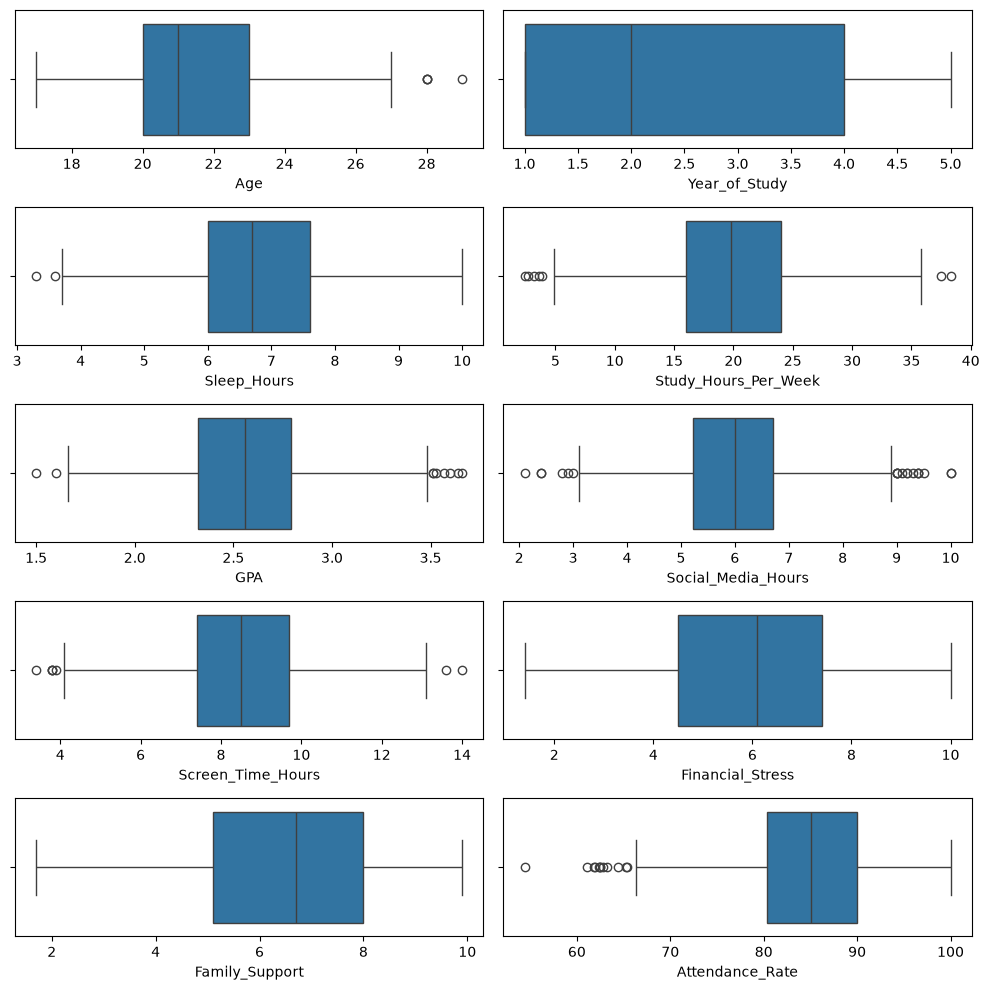

In [97]:
# Vérification des valeurs aberrantes
fig, axes = plt.subplots(5, 2, figsize=(10,10))
for i, col in enumerate(num_cols):
    sn.boxplot(
        data=X[[col]],
        x=col,
        meanline=True,
        orientation="horizontal",
        ax=axes[i//2, i%2],
    )

plt.tight_layout()
plt.show()

- Âge :
    * La majorité des âges se situe approximativement entre 20 et 23 ans.
    * La moustache supérieure atteint environ 27 ans.
    * Deux valeurs aberrantes apparaissent autour de 28 et 29 ans.
<p style="color:red;">
    si on considère la contrainte 1 ans pour entrer à la faculté avec 4 ans de redoublement (2 pour licence;+1 en cas d'execption et 1 pour le master) ça sera logique d'arrêter à 27 ans.
</p>

- Année d'étude :
    * Les valeurs sont comprises entre 1 et 5.
    * Des cas limités qui tendent pour le master.
<p style="color:green;">
    La distribution est cohérente avec un cursus de 5 années (Licence + Master).
</p>

- Heures de couché :
    * La majorité des observations se situe approximativement entre 6 et 8 heures.
    * Des valeurs inférieures à environ 3,75 heures sont identifiées comme aberrantes.
<p style="color:green;">
    détecter à deux Cycles du sommeil; logique. Pour la borne sup :10, c'est la convention d'un bon sommeil.
</p>

- Heures d'étude personnelle : 
    * toute valeur hors de l'intervalle [5, 36] est consédérée comme valeur aberrante.
    * La majorité des observations se situe approximativement entre 16 et 24 heures par semaine.
<p style="color:green;">  
Les étudiants qui consacrent très peu ou beaucoup de temps aux études personnelles présentent des comportements minoritaires dans le dataset (environ 7 observations).<br>
L'intervalle statistique approximatif est [5, 36], mais cela ne constitue pas une limite absolue du temps d'étude possible.
</p>

- GPA :
    * La majorité des observations se situe entre environ 2,3 et 2,8.
    * Quelques valeurs aberrantes basses autour de 1,5–1,6 sont détectées.
    * Quelques valeurs aberrantes élevées autour de 3,5–3,7 sont également détectées.
<p style="color:green;">
Ces étudiants présentent des performances académiques éloignées de la majorité.<br>
Toutefois, si le GPA est défini sur une échelle de 0 à 4, ces valeurs restent parfaitement possibles.
</p>

- Heures sur RS :
    * La majorité des observations se situe entre environ 5 et 7 heures.
    * Des valeurs aberrantes faibles autour de 2–3 heures sont détectées.
    * Des valeurs aberrantes élevées autour de 9–10 heures sont également détectées.

- Heures sur (ordinateur/téléphone) :
    * La majorité des observations se situe approximativement entre 7 et 10 heures.
    * Des valeurs aberrantes inférieures à environ 4 heures sont détectées.
    * Quelques valeurs aberrantes supérieures à environ 13 heures sont également détectées.

- Stresse financiale :
    * Les valeurs sont comprises entre 1 et 10.
    * La médiane se situe autour de 6.
    * Aucune valeur aberrante n'est détectée.

- Support familiale :
    * Les valeurs sont comprises entre 1 et 10.
    * La médiane se situe autour de 7.
    * Aucune valeur aberrante n'est détectée.

- Présence aux classes :
    * La majorité des observations se situe approximativement entre 80 % et 90 %.
    * Quelques valeurs aberrantes inférieures à environ 67 % sont détectées.
<p style="color:green;">
Ces valeurs restent possibles : un étudiant peut avoir un taux de présence faible sans que ses données soient incorrectes.
</p>